# 05 · Beam search

**The question.** If greedy is short-sighted, why not search for the most probable *whole sequence*?

**The claim.** Beam search does that: it keeps the B best partial sequences at every step and returns the most probable finished one. It finds text the model rates more likely than greedy's, which is what you want when there is one right answer (translation, extraction). On open-ended prompts the same objective produces safe, high-probability text that is identical on every run. Optimising for probability and optimising for interestingness are different goals.

**By the end** you will have a beam search that matches `transformers` token for token, and a measured picture of where it wins and where it loses.

*Outputs:* `outputs/figures/05_*.png` and `outputs/results/05_*.json`.

In [1]:
import inspect
import textwrap

import pandas as pd
import torch

from src.config import get_settings

S = get_settings()
SEED = S.seed
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
print(f"seed = {SEED}  (config/settings.yaml)")

from src.results import save_json
from src.visualisation import save_figure

seed = 42  (config/settings.yaml)


## 1. The algorithm

At every step: extend each of the B live sequences by every token, score each candidate by its *accumulated* log-probability, keep the best B. A candidate that ends (EOS or the length limit) moves to a finished pool, scored by its log-probability divided by its generated length (`length_penalty = 1`). The bookkeeping (2B candidates per step, only the top B may finish, the default stopping rule) mirrors `transformers` so the two can be compared token for token.

In [2]:
from src.decoders import beam_search

src = inspect.getsource(beam_search)
print(src[src.index("    if input_ids.dim()") :])

    if input_ids.dim() != 2 or input_ids.size(0) != 1:
        raise ValueError("beam_search decodes one prompt at a time: input_ids must be (1, seq)")
    if num_beams < 1 or max_new_tokens < 1:
        raise ValueError("num_beams and max_new_tokens must both be >= 1")

    # transformers keeps max(2, 1 + n_eos) * B candidates; with one EOS id that is 2B.
    n_candidates = 2 * num_beams
    running = input_ids
    running_scores = torch.zeros(1)
    finished: list[tuple[Tensor, float]] = []

    for step in range(max_new_tokens):
        generated = step + 1
        logprobs = torch.log_softmax(model.next_token_logits(running), dim=-1)
        vocab = logprobs.size(-1)
        totals = (running_scores[:, None] + logprobs).flatten()
        cand_scores, cand_idx = torch.topk(totals, min(n_candidates, totals.numel()))
        beam_idx = torch.div(cand_idx, vocab, rounding_mode="floor")
        tokens = cand_idx % vocab
        cand_seqs = torch.cat([running[beam_idx], tokens[:, None]],

## 2. Wider beams find more probable text

In [3]:
import math

from src.analysis import repetition_metrics, sequence_logprob
from src.datasets import char_prompts
from src.decoders import BeamSearch, Decoder, make_generator
from src.model import default_char_lm

model = default_char_lm()
N_NEW = S.generation.max_new_tokens
rows = []
for b in S.decoding.beam_widths:
    for p in char_prompts("open"):
        ids = model.encode(p.text)
        out = BeamSearch(b).generate(model, ids, N_NEW)
        rows.append({"beam_width": b, "prompt": p.text,
                     "mean_logprob": sequence_logprob(model, out, ids.size(1)),
                     **repetition_metrics(model.decode(out[0, ids.size(1):]))})
by_prompt = pd.DataFrame(rows)
by_width = by_prompt.groupby("beam_width", as_index=False)[["mean_logprob", "distinct_2"]].mean()
by_width["likelihood"] = by_width["mean_logprob"].map(math.exp)
by_width.round(3)

,beam_width,mean_logprob,distinct_2,likelihood
0,1,-0.129,0.364,0.879
1,2,-0.077,0.956,0.926
2,4,-0.071,0.612,0.931
3,8,-0.067,0.765,0.936


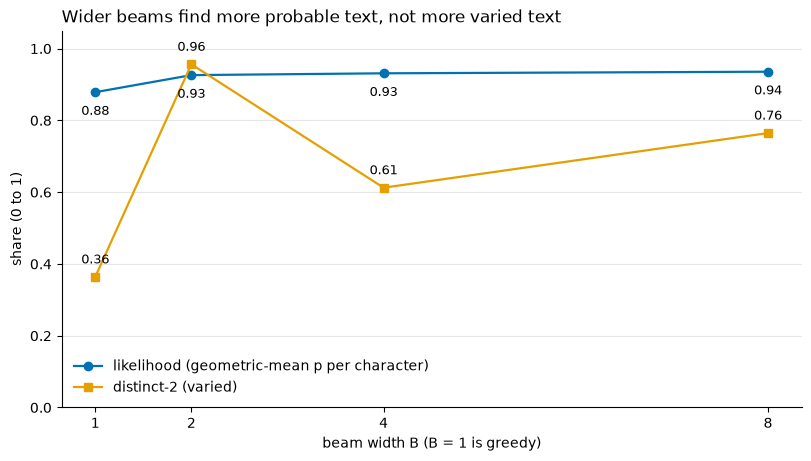

In [4]:
from src.visualisation import plot_metrics_vs

fig = plot_metrics_vs(
    by_width, "beam_width",
    {"likelihood": "likelihood (geometric-mean p per character)",
     "distinct_2": "distinct-2 (varied)"},
    xlabel="beam width B (B = 1 is greedy)", ylabel="share (0 to 1)",
    title="Wider beams find more probable text, not more varied text",
    annotate={"likelihood": -14, "distinct_2": 12},
)
fig.axes[0].set_xticks(S.decoding.beam_widths)
fig.axes[0].set_ylim(0, 1.05)
save_figure(fig, "05_beam_width")
save_json("05_beam_width", {"max_new_tokens": N_NEW, "by_width": by_width, "by_prompt": by_prompt});

Likelihood rises monotonically with beam width: that is the objective, and beam search delivers it. Distinct-2 does not follow any clean trend. B = 2 happens to escape greedy's attractor on these prompts, B = 4 and B = 8 are more repetitive again. **Beam width is a likelihood knob, not a diversity knob.** Whatever variety it produces is incidental, and it is the same on every run.

In [5]:
p = char_prompts("open")[0]
ids = model.encode(p.text)
beam_vs_nucleus = {}
for strategy in [BeamSearch(S.decoding.default_beam_width), Decoder.nucleus(S.decoding.default_top_p)]:
    out = strategy.generate(model, ids, 200, generator=make_generator(SEED))
    beam_vs_nucleus[strategy.label] = model.decode(out[0, ids.size(1):])
    print(f"--- {strategy.label}\n{textwrap.fill(p.text + beam_vs_nucleus[strategy.label], 110)}\n")

--- beam (B=4)
the keeper climbed the stairs and lit the lamp and looked out over the water. the sea. every night the keeper
climbed the stairs and lit the lamp and looked out over the water. the sea. in the morning he walked

--- T=1, top-p=0.8
the keeper saw him from the hills above the sea. every night the keeper climbed the stairs and lit the lamp
and looked out over the water. the sea. every night the keeper grew old and the gulls laughed at the r



## 3. The arena: same model, every decoder, both kinds of task

Every standard decoder on all eleven char-model prompts. Deterministic decoders run once per prompt, stochastic ones five times.

In [6]:
from src.evaluation import corpus_lexicon, run_arena, standard_strategies, summarize_arena

strategies = standard_strategies(S)
arena = run_arena(model, char_prompts(), strategies, n_samples=S.generation.n_samples,
                  max_new_tokens=N_NEW, seed=SEED, lexicon=corpus_lexicon())
summary = summarize_arena(arena, S.generation.n_samples)
summary["open_likelihood"] = summary["open_logprob"].map(math.exp)
cols = ["single_accuracy", "open_score", "open_distinct_2", "open_valid_words",
        "open_diversity", "open_likelihood"]
summary[cols].round(3)

,single_accuracy,open_score,open_distinct_2,open_valid_words,open_diversity,open_likelihood
decoder,,,,,,
greedy,1.0,0.359,0.364,0.987,0.073,0.879
"greedy, rep=1.3",1.0,0.690,0.699,0.987,0.140,0.888
beam (B=4),1.0,0.610,0.612,0.997,0.122,0.931
T=1,1.0,0.827,0.911,0.908,0.720,0.756
T=2,0.2,0.292,0.998,0.293,0.987,0.123
"T=1, top-k=5",1.0,0.829,0.893,0.928,0.725,0.804
"T=1, top-p=0.8",1.0,0.852,0.861,0.990,0.658,0.891


## 4. The decoder that wins one task loses the other

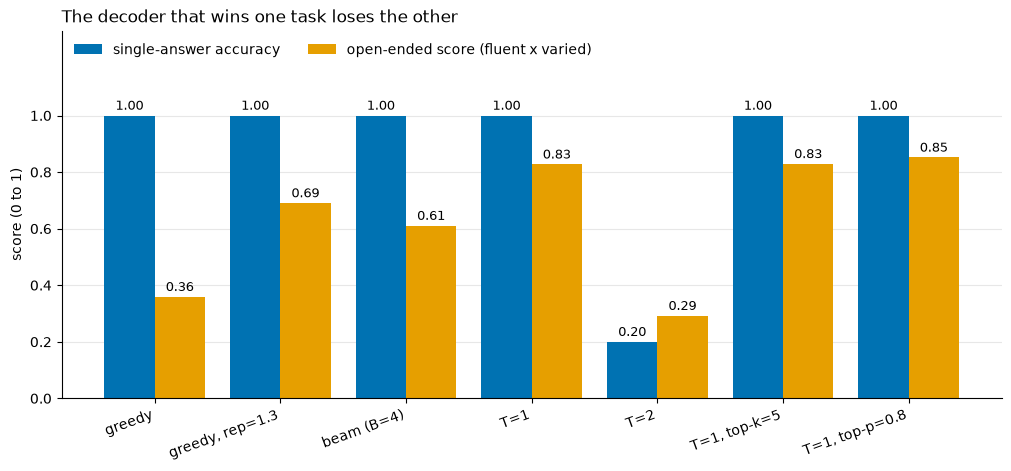

In [7]:
from src.visualisation import plot_task_tradeoff

fig = plot_task_tradeoff(summary)
save_figure(fig, "05_task_tradeoff")
save_json("05_arena", {
    "n_samples": S.generation.n_samples, "max_new_tokens": N_NEW, "summary": summary[cols],
    "samples": arena[["prompt", "kind", "decoder", "sample", "completion", "correct"]],
});

On single-answer prompts the deterministic decoders (greedy, penalised greedy, beam) are perfect and high-temperature sampling is not. On open-ended prompts the ranking flips: the sampling decoders with a tail cut score highest on "fluent × varied", while greedy and beam fall behind because they repeat.

## 5. Quality versus diversity

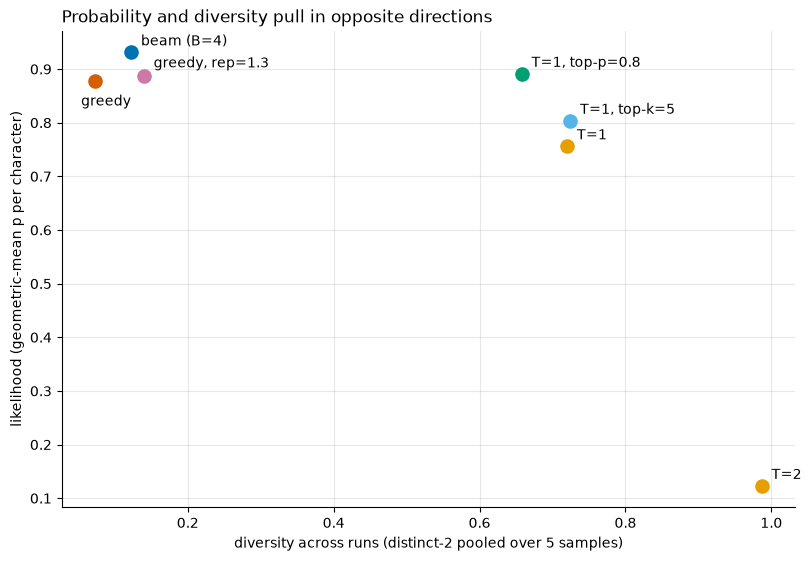

In [8]:
from src.visualisation import plot_quality_diversity

fig = plot_quality_diversity(
    summary, x="open_diversity", y="open_likelihood",
    xlabel="diversity across runs (distinct-2 pooled over 5 samples)",
    ylabel="likelihood (geometric-mean p per character)",
    title="Probability and diversity pull in opposite directions",
    label_offsets={"greedy": (-10, -18), "greedy, rep=1.3": (7, 6)},
)
save_figure(fig, "05_quality_diversity")
save_json("05_quality_diversity", summary[["open_diversity", "open_likelihood", "open_valid_words"]]);

Top-left: beam search, which finds the most probable text by construction, and greedy. Both say the same thing on every run, so their diversity across runs is near zero. Bottom-right: T = 2, maximally diverse and improbable, i.e. gibberish. The useful decoders sit along the frontier between them.

Two details worth noticing. Greedy is *not* the most probable sequence, despite taking the top token at every step: its loop keeps revisiting forks where even the best character has p ≈ 0.2, which is exactly the short-sightedness beam search fixes. And nucleus sampling at p = 0.8 reaches about the same likelihood as greedy while being roughly nine times as diverse across runs. High likelihood and good text are different things (Holtzman et al., 2020).

## 6. Explore versus exploit

This is the trade-off from `bandits_101` in a new setting. Greedy and beam search are pure exploitation: always take what currently looks best. Sampling with temperature is exactly Boltzmann (softmax) exploration, the same formula with the same knob: low temperature exploits, high temperature explores. Top-p plays the role of refusing to explore arms that are clearly bad. A single-answer task is a bandit with one arm worth pulling, so exploration only costs reward. An open-ended task rewards coverage, so some exploration is the point.

## 7. On a real model: identical to `transformers`, same trade-off

In [9]:
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

from src.model import load_model

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()
hf = load_model("hf")  # distilgpt2: ~350 MB on first use, cached afterwards

In [10]:
from src.evaluation import compare_generation

ref_prompt = "Monday, Tuesday, Wednesday,"
reference = compare_generation(hf, hf.encode(ref_prompt), max_new_tokens=15, beam_widths=(2, 4))
assert reference["identical"].all()
save_json("05_distilgpt2_vs_transformers", {"model": hf.name, "prompt": ref_prompt,
                                            "max_new_tokens": 15, "checks": reference})
reference

,decoder,tokens_ours,tokens_transformers,identical
0,greedy,15,15,True
1,"greedy, rep=1.3",15,15,True
2,beam (B=2),15,15,True
3,beam (B=4),15,15,True


In [11]:
from src.datasets import hf_prompts

hf_strategies = [Decoder.greedy(), BeamSearch(4), Decoder.nucleus(0.9), Decoder.sampling(1.5)]
hf_arena = run_arena(hf, hf_prompts(), hf_strategies, n_samples=3, max_new_tokens=40,
                     max_new_tokens_single=4, seed=SEED, score_quality=False)
hf_summary = summarize_arena(hf_arena, n_samples=3)
save_json("05_distilgpt2_arena", {
    "model": hf.name, "n_samples": 3, "max_new_tokens": 40,
    "summary": hf_summary[["single_accuracy", "open_distinct_2", "open_diversity"]],
    "samples": hf_arena[["prompt", "kind", "decoder", "sample", "completion", "correct"]],
})
hf_summary[["single_accuracy", "open_distinct_2", "open_diversity"]].round(2)

,single_accuracy,open_distinct_2,open_diversity
decoder,,,
greedy,1.00,0.18,0.06
beam (B=4),1.00,0.72,0.24
"T=1, top-p=0.9",0.44,0.99,0.98
T=1.5,0.00,1.00,1.00


In [12]:
for _, row in hf_arena[(hf_arena["sample"] == 0)].iterrows():
    if row["prompt"] in (hf_prompts("single")[0].text, hf_prompts("open")[1].text):
        print(f"[{row['decoder']}] {row['prompt']}{row['completion']!r}")

[greedy] Once upon a time, in a small village by the sea,' a man, a woman, a man, a man, a man, a man, a man, a man, a man, a man, a man, a man, a man, a'
[beam (B=4)] Once upon a time, in a small village by the sea,' there was a man who had been waiting for a day.\n\n\n※\n※\n※\n※\n※\n※\n※\n※\n�'
[T=1, top-p=0.9] Once upon a time, in a small village by the sea," I would first work with Norvalon, who would pass by the low wind and would place my lantern in his hand. I looked into the village's skies, and several others. Without seeing Nor"
[T=1.5] Once upon a time, in a small village by the sea,' Juno bound objects to travellers at Intoreo, Zurich, Vice La Lines and Infal Publishing Co. farewell Yamato filletteur It AC 630 Thomas Colombas Sal Ruselve Dalou CR Alexandria'
[greedy] Monday, Tuesday, Wednesday,' Thursday, Friday,'
[beam (B=4)] Monday, Tuesday, Wednesday,' Thursday, Friday,'
[T=1, top-p=0.9] Monday, Tuesday, Wednesday,' Friday and Saturday,'
[T=1.5] Monday, Tuesday, Wednesda

The real model repeats the pattern. Greedy and beam get the weekday right every time, while sampling sometimes skips a day. On the open prompt greedy loops ("a man, a man, a man") and nucleus sampling writes something new on each run. Beam's distinct-2 of 0.72 flatters it, though: read its completion and it degenerates into a run of `※` symbols, a loop that word-level metrics cannot see. Always read the text next to the numbers.

## What this bought you

- Beam search maximises sequence probability, and wider beams do find more probable text. It matches `transformers.generate(num_beams=B)` token for token, EOS handling included (also asserted in `tests/test_vs_reference.py`).
- On single-answer prompts, maximising probability is the right goal: beam and greedy are perfect where sampling is not.
- On open-ended prompts, the most probable text is repetitive and identical across runs. Probability and diversity trade off, the same explore-exploit tension as in bandits.

Next: [06 · Decision framework](06_decision_framework.ipynb), which turns all of this into rules.